## 라이브러리 설치 & Import

In [1]:
#!pip install matplotlib

In [2]:
# 데이터 처리 및 분석
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import warnings

# 시각화
import matplotlib.pyplot as plt
import seaborn as sns

# 통계 분석
from scipy import stats
from scipy.stats import shapiro, levene, ttest_ind, chi2_contingency, f_oneway
from scipy.stats import mannwhitneyu, fisher_exact, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd, MultiComparison
import pingouin as pg

# 출력 설정
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# 한글 폰트 설정
import platform
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':  # maxOS
    plt.rcParams['font.family'] = 'AppleGothic'
else:  # Linux
    plt.rcParams['font.family'] = 'NanumGothic'
    
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 6)

# 시드 설정
np.random.seed(42)

print("="*60)
print("라이브러리 로드 완료!")
print("한글 폰트 설정 완료!")
print("="*60)

라이브러리 로드 완료!
한글 폰트 설정 완료!


## 데이터 로드

In [3]:
# 데이터 로드
df_articles = pd.read_csv('./datasets/articles_hm.csv')
df_customer = pd.read_csv('./datasets/customer_hm.csv')
df_transaction = pd.read_csv('./datasets/transactions_hm.csv')

## 데이터 조회

In [4]:
df_customer

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,0,0,ACTIVE,NONE,49
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,0,0,ACTIVE,NONE,25
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0,0,ACTIVE,NONE,24
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,0,0,ACTIVE,NONE,54
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1,1,ACTIVE,Regularly,52
...,...,...,...,...,...,...
1048570,c88f5971612e659a4e90d6f08d9c29bdf1e4268fcf52d5...,1,1,ACTIVE,Regularly,22
1048571,c88f5d0deba322a686e7928da6a7f3d2318e102d1c2cdb...,1,1,ACTIVE,Regularly,41
1048572,c88f99a55b10f6dd50dd87c3ca05af4a8a6c98f3e6fbc5...,0,0,ACTIVE,NONE,38
1048573,c88fa15c06519c4bdcab386fea313b226113584b729874...,1,1,ACTIVE,Regularly,54


#### 행, 열 개수 조회

In [5]:
print("데이터 모양(행, 열):", df_customer.shape)

데이터 모양(행, 열): (1048575, 6)


#### 상위 5개, 하위 5개 데이터 조회

In [6]:
display(df_customer.head())
display(df_customer.tail())

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,0,0,ACTIVE,NONE,49
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,0,0,ACTIVE,NONE,25
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0,0,ACTIVE,NONE,24
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,0,0,ACTIVE,NONE,54
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1,1,ACTIVE,Regularly,52


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age
1048570,c88f5971612e659a4e90d6f08d9c29bdf1e4268fcf52d5...,1,1,ACTIVE,Regularly,22
1048571,c88f5d0deba322a686e7928da6a7f3d2318e102d1c2cdb...,1,1,ACTIVE,Regularly,41
1048572,c88f99a55b10f6dd50dd87c3ca05af4a8a6c98f3e6fbc5...,0,0,ACTIVE,NONE,38
1048573,c88fa15c06519c4bdcab386fea313b226113584b729874...,1,1,ACTIVE,Regularly,54
1048574,c88fa6553539a079a4d49f5b6d286d33bdc7117d0acbb9...,0,0,ACTIVE,NONE,49


#### 컬럼명 조회

In [7]:
df_customer.columns

Index(['customer_id', 'FN', 'Active', 'club_member_status',
       'fashion_news_frequency', 'age'],
      dtype='str')

#### 전체 구조 파악
- (행/열 개수, 컬럼별 데이터 타입, non-null 개수 조회)

In [8]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 6 columns):
 #   Column                  Non-Null Count    Dtype
---  ------                  --------------    -----
 0   customer_id             1048575 non-null  str  
 1   FN                      1048575 non-null  int64
 2   Active                  1048575 non-null  int64
 3   club_member_status      1048575 non-null  str  
 4   fashion_news_frequency  1048574 non-null  str  
 5   age                     1048575 non-null  int64
dtypes: int64(3), str(3)
memory usage: 48.0 MB


#### 각 컬럼별 결측치 개수 확인

In [9]:
df_customer.isna().sum()

customer_id               0
FN                        0
Active                    0
club_member_status        0
fashion_news_frequency    1
age                       0
dtype: int64

#### 값의 분포, 통계치 확인
- (count, mean, std, min, 25%, 50%, 75%, max)

In [10]:
df_customer.describe()

,FN,Active,age
count,1.048575e+06,1.048575e+06,1.048575e+06
mean,3.555397e-01,3.461326e-01,3.636919e+01
std,4.786767e-01,4.757363e-01,1.430899e+01
min,0.000000e+00,0.000000e+00,1.600000e+01
25%,0.000000e+00,0.000000e+00,2.400000e+01
50%,0.000000e+00,0.000000e+00,3.200000e+01
75%,1.000000e+00,1.000000e+00,4.900000e+01
max,1.000000e+00,1.000000e+00,9.900000e+01


#### Grain(식별 기준) 파악하기
- 식별자(Primary Key) 찾기
    - `id`, `code`, `no`

In [11]:
# 전체 행 개수
total_rows = len(df_customer)
print(f"전체 행 개수: {total_rows}\n")

# ID로 추정되는 주요 컬럼들의 유일값 개수 확인
for col in df_customer.columns:
    if 'id' in col.lower() or 'code' in col.lower() or 'no' in col.lower():
        unique_cnt = df_customer[col].nunique()
        print(f"컬럼 [{col}]의 유일값 개수: {unique_cnt} (전체 행 대비 비중: {unique_cnt/total_rows*100:.1f}%)")

전체 행 개수: 1048575

컬럼 [customer_id]의 유일값 개수: 1048575 (전체 행 대비 비중: 100.0%)


#### 결측치 비율 파악

In [12]:
# 컬럼별 결측치 개수 및 비율 확인
null_PCT = pd.DataFrame({
    '결측치_개수': df_customer.isnull().sum(),
    '결측치_비율(%)': (df_customer.isnull().sum() / len(df_customer) * 100).round(2)
})

# 결측치가 1개 이상 있는 컬럼만 출력
null_PCT[null_PCT['결측치_개수'] > 0]

,결측치_개수,결측치_비율(%)
fashion_news_frequency,1,0.0


#### 수치 기반 이상치 및 분포 확인

In [13]:
# 1. 수치형 컬럼 전체의 요약 통계량 확인
display(df_customer.describe().T)

# 2. 수치형 컬럼만 자동 추출한 뒤, 전체 분위수(Quantile) 확인
numeric_df = df_customer.select_dtypes(include=['number'])

# 수치형 컬럼이 1개라도 존재하는지 체크
if not numeric_df.empty:
    print("--- 모든 수치형 컬럼의 상세 분위수 확인 ---")
    # numeric_df 자체에 .quantile()을 적용하면 모든 수치형 컬럼이 한눈에 조회 가능
    display(numeric_df.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]))
else:
    print("이 데이터에는 수치형 컬럼이 없습니다.")

,count,mean,std,min,25%,50%,75%,max
FN,1048575.0,0.355540,0.478677,0.0,0.0,0.0,1.0,1.0
Active,1048575.0,0.346133,0.475736,0.0,0.0,0.0,1.0,1.0
age,1048575.0,36.369194,14.308991,16.0,24.0,32.0,49.0,99.0


--- 모든 수치형 컬럼의 상세 분위수 확인 ---


,FN,Active,age
0.01,0.0,0.0,18.0
0.05,0.0,0.0,19.0
0.25,0.0,0.0,24.0
0.50,0.0,0.0,32.0
0.75,1.0,1.0,49.0
0.95,1.0,1.0,62.0
0.99,1.0,1.0,71.0
1.00,1.0,1.0,99.0


#### 시각화를 활용한 이상치 탐색 (Boxplot)
- `나이('age')`

자동 추출된 수치형 컬럼 목록: ['FN', 'Active', 'age']


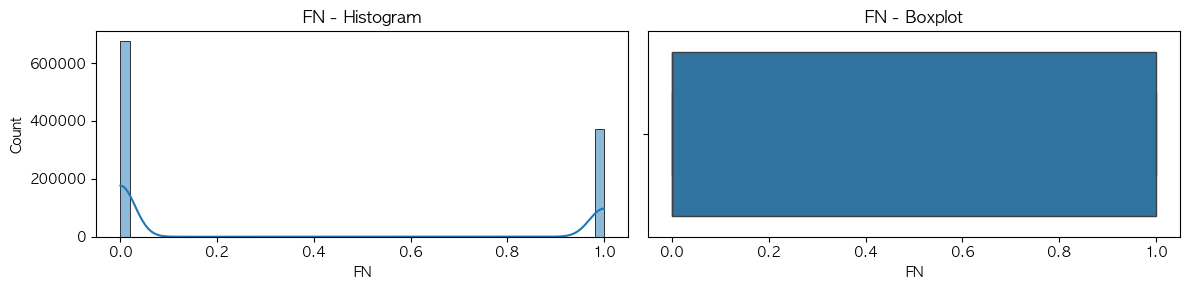

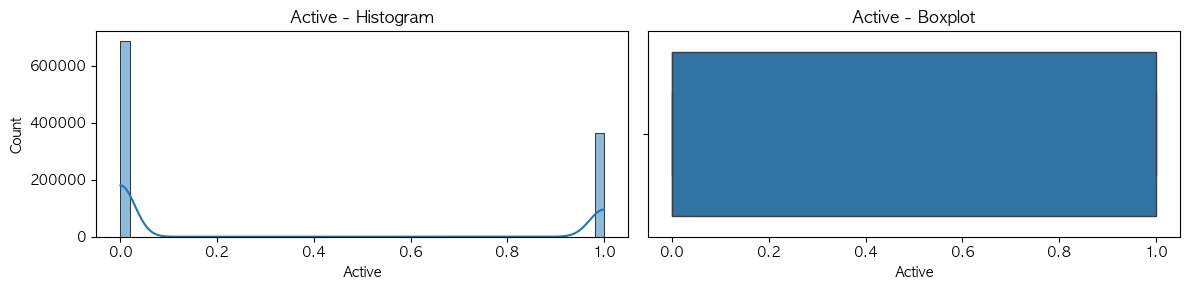

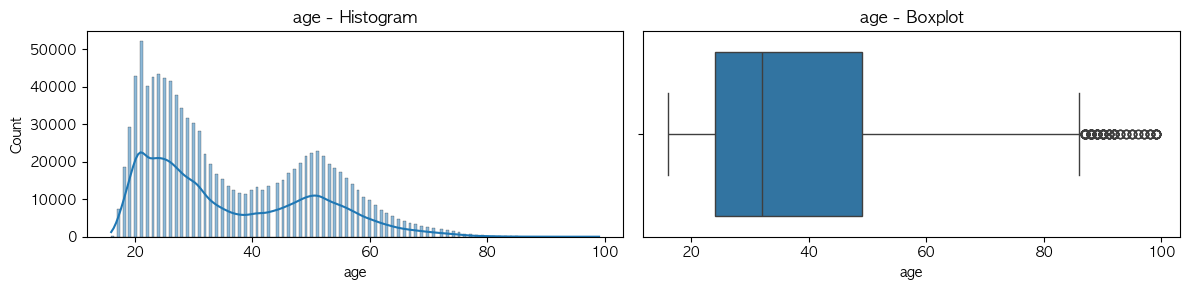

In [14]:
# 수치형 컬럼만 자동으로 추출 (ID처럼 의미 없는 숫자는 제외하고 싶다면 아래에서 자동 제거)
numeric_cols = df_customer.select_dtypes(include=["number"]).columns.tolist()

# ID 관련 컬럼은 시각화에서 제외 (컬럼명에 'id'가 들어간 경우 자동 제외)
numeric_cols = [col for col in numeric_cols if "id" not in col.lower()]

print(f"자동 추출된 수치형 컬럼 목록: {numeric_cols}")

# 2. 추출된 수치형 컬럼들을 순회하며 자동으로 시각화
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))

    # 왼쪽: 히스토그램 (분포 확인)
    sns.histplot(data=df_customer, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f"{col} - Histogram")

    # 오른쪽: 박스플롯 (이상치 및 쏠림 확인)
    sns.boxplot(data=df_customer, x=col, ax=axes[1])
    axes[1].set_title(f"{col} - Boxplot")

    plt.tight_layout()
    plt.show()

In [15]:
# 1. 사분위수(Q1, Q3) 및 중위수 계산
q1 = df_customer['age'].quantile(0.25)
q3 = df_customer['age'].quantile(0.75)
median = df_customer['age'].median()

# 2. IQR(Q3 - Q1) 및 박스플롯 상한선 계산
iqr = q3 - q1
upper_bound = q3 + (1.5 * iqr)

# 3. 이상치 개수 및 비율 확인 (선택사항)
outliers = df_customer[df_customer['age'] > upper_bound]
outlier_ratio = (len(outliers) / len(df_customer)) * 100

print(f"Q1 (하위 25%): {q1:.3f}")
print(f"중위수 (50%): {median:.3f}")
print(f"Q3 (상위 25%): {q3:.3f}")
print(f"이상치 판단 상한선 (Q3 + 1.5*IQR): {upper_bound:.3f}")
print(f"이상치 비율: {outlier_ratio:.2f}%")

Q1 (하위 25%): 24.000
중위수 (50%): 32.000
Q3 (상위 25%): 49.000
이상치 판단 상한선 (Q3 + 1.5*IQR): 86.500
이상치 비율: 0.02%


#### 숨은 결측치 문자 체크

In [17]:
# 1. 범주형(문자형) 컬럼 목록 자동 추출
cat_cols = df_customer.select_dtypes(include=['object', 'category']).columns

# 2. 체크하고 싶은 '숨은 결측치 문자' 목록
missing_indicators = ['Unknown', 'unknown', 'None', '-', '?']

print("=== 범주형 컬럼 내 텍스트 결측치 점검 결과 ===")

# 모든 범주형 컬럼을 돌면서 확인
for col in cat_cols:
    for indicator in missing_indicators:
        # 해당 문자가 들어있는 개수 세기
        count = (df_customer[col] == indicator).sum()
        
        # 1개라도 발견되면 출력
        if count > 0:
            print(f"[{col}] 컬럼에 '{indicator}' 값이 {count}개 존재합니다.")

=== 범주형 컬럼 내 텍스트 결측치 점검 결과 ===


#### 오탈자 및 띄어쓰기 문제 확인

In [18]:
# 모든 범주형 컬럼에 대해 공백 문제 및 오탈자 가능성 점검
for col in cat_cols:
    original_nunique = df_customer[col].nunique()
    
    # 양쪽 공백을 제거(.str.strip())했을 때의 종류 수 계산
    cleaned_nunique = df_customer[col].astype(str).str.strip().nunique()
    
    if original_nunique != cleaned_nunique:
        print(f" [{col}] 컬럼: 띄어쓰기/공백 문제 존재")
        print(f"  - 원본 종류 수: {original_nunique}개 -> 공백 제거 후: {cleaned_nunique}개")

#### 클래스 불균형 (한 항목 99% 독점) 확인하기
- 분석 가치 없는 컬럼이라 삭제해야 함

In [19]:
print("=== 클래스 불균형 (특정 항목 95% 이상 독점) 점검 ===")

for col in cat_cols:
    # normalize=True를 주면 비율(0~1)로 나옴
    top_ratio = df_customer[col].value_counts(normalize=True, dropna=False).iloc[0]
    top_value = df_customer[col].value_counts(dropna=False).index[0]
    
    # 1등 항목이 전체의 95%(0.95) 이상을 차지하는 경우 경고 출력
    if top_ratio >= 0.95:
        print(f" [{col}] 컬럼: 클래스 불균형 존재")
        print(f"  - 가장 많은 값: '{top_value}' ({top_ratio*100:.1f}%)")

=== 클래스 불균형 (특정 항목 95% 이상 독점) 점검 ===


#### 중복 데이터 조회 및 처리

In [20]:
# 전체 테이블에서 완전히 똑같은 중복 행이 몇 개 있는지 확인
print("완전 중복 행 개수:", df_customer.duplicated().sum())

# 중복 데이터만 뽑아서 customer_id 순으로 정렬해서 보기
duplicate_rows = df_customer[df_customer.duplicated(keep=False)]
display(duplicate_rows.sort_values(by=['customer_id']).head(10))

# df_customer PK인 customer_id가 중복된 적이 있는지 확인
print("customer_id 중복 개수:", df_customer.duplicated(subset=['customer_id']).sum())

완전 중복 행 개수: 0


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age


customer_id 중복 개수: 0


#### 수치 간 상관관계 히트맵

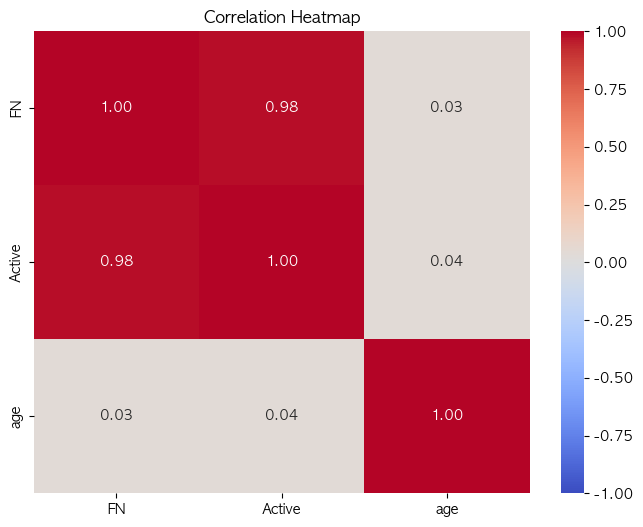

In [23]:
# df에서 수치형 컬럼만 자동으로 추출
numeric_cols = df_customer.select_dtypes(include=["number"]).columns.tolist()

# 수치형 변수 간 상관계수 히트맵
plt.figure(figsize=(8, 6))
sns.heatmap(
    df_customer[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Heatmap")
plt.show()

#### 범주형 변수 비중 확인

시각화에 적합한 범주형 컬럼 목록: ['club_member_status', 'fashion_news_frequency']


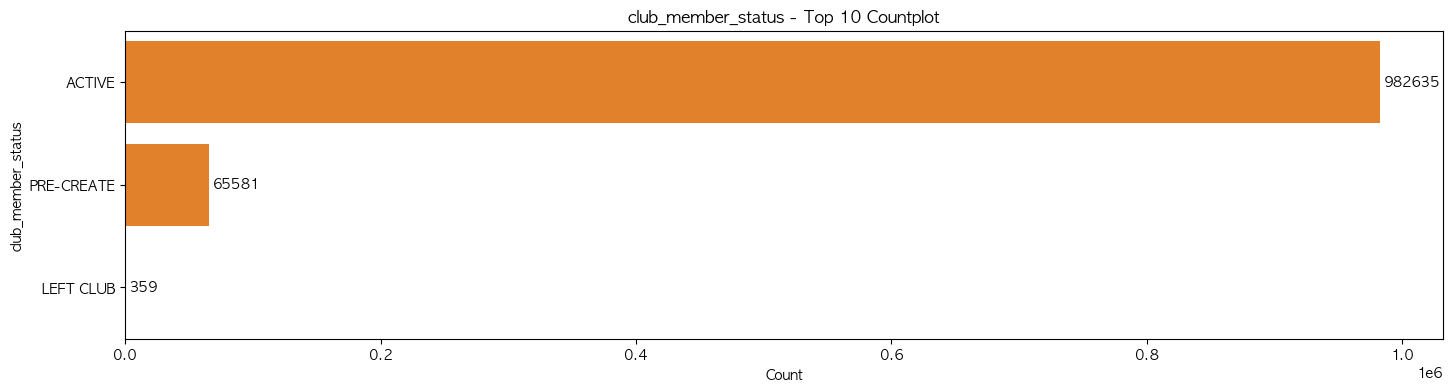

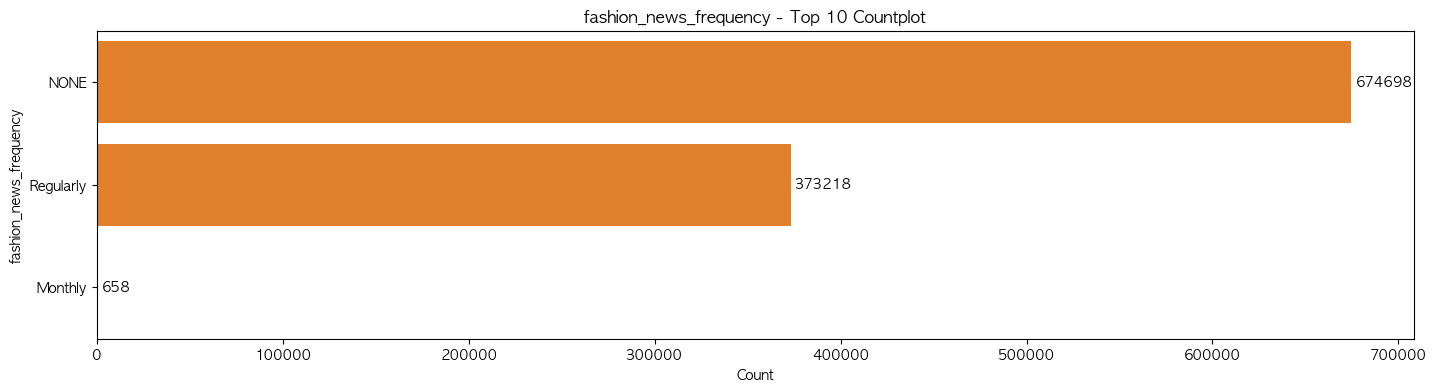

In [26]:
# 글자(범주형) 컬럼만 추출
cat_cols = df_customer.select_dtypes(include=["object", "category"]).columns.tolist()

# 고유값(종류)이 너무 많은 컬럼(예: 30개 초과) 및 ID/설명 컬럼 자동 제외
filtered_cat_cols = [col for col in cat_cols
    if df_customer[col].nunique() <= 30  # 카테고리 종류가 30개 이하인 것만 선별
    and not any(k in col.lower() for k in ["id", "code", "no", "desc", "name_length"])]

print("시각화에 적합한 범주형 컬럼 목록:", filtered_cat_cols)

# 선별된 진짜 범주형 컬럼들만 countplot 그리기
for col in filtered_cat_cols:
    plt.figure(figsize=(17, 4))
    # 데이터 상위 10개만 골라 시각화
    top_10 = df_customer[col].value_counts().head(10).index
    sns.countplot(
        data=df_customer[df_customer[col].isin(top_10)],
        y=col,
        order=top_10,)
    
    ax = sns.countplot(
        data=df_customer[df_customer[col].isin(top_10)],
        y=col,
        order=top_10,)
    
    ax.bar_label(ax.containers[0], fmt="%d", padding=3)

    plt.title(f"{col} - Top 10 Countplot")
    plt.xlabel("Count")
    plt.show()

#### 범주형 데이터 고유값 빈도수(개수) 확인(결측치 제외)

In [28]:
# 제외할 컬럼 목록 직접 지정 (detail_desc, customer_id 등)
exclude_cols = ['detail_desc', 'customer_id']

# 범주형 컬럼 중 제외 목록만 빼고 선택
categorical_cols = [c for c in df_customer.select_dtypes(include=['object', 'category']).columns if c not in exclude_cols]

# 고유값 빈도 및 비율 출력
for col in categorical_cols:
    print(f"=== {col} ===")
    counts = df_customer[col].value_counts()  # dropna=True (기본값)
    probs = df_customer[col].value_counts(normalize=True) * 100
    
    summary = pd.DataFrame({'Count': counts, 'Percentage (%)': probs.round(2)})
    display(summary)
    print("\n")

=== club_member_status ===


,Count,Percentage (%)
club_member_status,,
ACTIVE,982635,93.71
PRE-CREATE,65581,6.25
LEFT CLUB,359,0.03




=== fashion_news_frequency ===


,Count,Percentage (%)
fashion_news_frequency,,
NONE,674698,64.34
Regularly,373218,35.59
Monthly,658,0.06
